In [23]:
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

In [24]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATASET_DIR = PROJECT_DIR / "data" / "fashion_mnist"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

for directory in [DATASET_DIR, CHECKPOINT_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

with open(PROJECT_DIR / "config.json", "r") as file:
    CONFIG = json.load(file)

GENERAL_CONFIG = CONFIG["general"]
SAE_CONFIG = CONFIG["models"]["sparse_ae"]

RANDOM_SEED = GENERAL_CONFIG["random_seed"]

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

if GENERAL_CONFIG["device"] == "auto":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
else:
    device = torch.device(GENERAL_CONFIG["device"])

print("Project Directory:", PROJECT_DIR)
print("Model: Sparse Autoencoder")
print("Available Device:", device)
print("Random Seed:", RANDOM_SEED)
print("Latent Dimension:", SAE_CONFIG["latent_dim"])
print("Sparsity Lambda:", SAE_CONFIG["sparsity_lambda"])

Project Directory: d:\generative-models-comparison
Model: Sparse Autoencoder
Available Device: cpu
Random Seed: 42
Latent Dimension: 64
Sparsity Lambda: 0.001


In [25]:
# Load Prepared Dataset
dataset_path = DATASET_DIR / "fashion_mnist_splits.pt"

dataset = torch.load(
    dataset_path,
    map_location="cpu",
    weights_only=True
)

# Extract Dataset Splits
train_images = dataset["train_images"]
val_images = dataset["val_images"]
test_images = dataset["test_images"]

# Display Dataset Information
print("Training Images:", train_images.shape)
print("Validation Images:", val_images.shape)
print("Testing Images:", test_images.shape)

Training Images: torch.Size([56000, 1, 28, 28])
Validation Images: torch.Size([7000, 1, 28, 28])
Testing Images: torch.Size([7000, 1, 28, 28])


In [26]:
# Normalize Images
train_images = train_images.float() / 255.0
val_images = val_images.float() / 255.0
test_images = test_images.float() / 255.0

# Flatten Images
train_images = train_images.view(-1, 784)
val_images = val_images.view(-1, 784)
test_images = test_images.view(-1, 784)

# Display Dataset Information
print("Training Shape:", train_images.shape)
print("Validation Shape:", val_images.shape)
print("Testing Shape:", test_images.shape)

print("\nPixel Value Range:")
print("Minimum:", train_images.min().item())
print("Maximum:", train_images.max().item())

Training Shape: torch.Size([56000, 784])
Validation Shape: torch.Size([7000, 784])
Testing Shape: torch.Size([7000, 784])

Pixel Value Range:
Minimum: 0.0
Maximum: 1.0


In [27]:
train_dataset = TensorDataset(train_images, train_images)
val_dataset = TensorDataset(val_images, val_images)
test_dataset = TensorDataset(test_images, test_images)

BATCH_SIZE = GENERAL_CONFIG["batch_size"]

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Batch Size:", BATCH_SIZE)
print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Batch Size: 128
Training Batches: 438
Validation Batches: 55
Testing Batches: 55


In [28]:
class SparseAutoencoder(nn.Module):
    def __init__(self, config):
        super(SparseAutoencoder, self).__init__()

        encoder_layers = []
        encoder_dims = config["encoder"]

        # Build Encoder
        for i in range(len(encoder_dims) - 1):
            encoder_layers.append(
                nn.Linear(encoder_dims[i], encoder_dims[i + 1])
            )

            if i < len(encoder_dims) - 2:
                encoder_layers.append(nn.ReLU())

        self.encoder = nn.Sequential(*encoder_layers)

        decoder_layers = []
        decoder_dims = config["decoder"]

        # Build Decoder
        for i in range(len(decoder_dims) - 1):
            decoder_layers.append(
                nn.Linear(decoder_dims[i], decoder_dims[i + 1])
            )

            if i < len(decoder_dims) - 2:
                decoder_layers.append(nn.ReLU())
            else:
                decoder_layers.append(nn.Sigmoid())

        self.decoder = nn.Sequential(*decoder_layers)

    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)

        return reconstructed, latent


# Initialize Model
model = SparseAutoencoder(SAE_CONFIG).to(device)

print(model)

SparseAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [29]:
# Reconstruction Loss
criterion = nn.MSELoss()

# Sparsity Weight
SPARSITY_LAMBDA = SAE_CONFIG["sparsity_lambda"]

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=SAE_CONFIG["learning_rate"]
)

# Training Configuration
EPOCHS = SAE_CONFIG["epochs"]

print("Reconstruction Loss:", criterion)
print("Sparsity Lambda:", SPARSITY_LAMBDA)
print("Optimizer:", optimizer)
print("Learning Rate:", SAE_CONFIG["learning_rate"])
print("Epochs:", EPOCHS)

Reconstruction Loss: MSELoss()
Sparsity Lambda: 0.001
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning Rate: 0.001
Epochs: 50


In [30]:
train_losses = []
val_losses = []

train_reconstruction_losses = []
train_sparsity_losses = []

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    # Training 
    model.train()

    running_train_loss = 0.0
    running_reconstruction_loss = 0.0
    running_sparsity_loss = 0.0

    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        reconstructed, latent = model(images)

        reconstruction_loss = criterion(reconstructed, targets)
        sparsity_loss = torch.mean(torch.abs(latent))

        total_loss = (
            reconstruction_loss
            + SPARSITY_LAMBDA * sparsity_loss
        )

        total_loss.backward()
        optimizer.step()

        running_train_loss += total_loss.item()
        running_reconstruction_loss += reconstruction_loss.item()
        running_sparsity_loss += sparsity_loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)
    epoch_reconstruction_loss = (
        running_reconstruction_loss / len(train_loader)
    )
    epoch_sparsity_loss = running_sparsity_loss / len(train_loader)

    train_losses.append(epoch_train_loss)
    train_reconstruction_losses.append(epoch_reconstruction_loss)
    train_sparsity_losses.append(epoch_sparsity_loss)

    # Validation 
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)

            reconstructed, latent = model(images)

            reconstruction_loss = criterion(reconstructed, targets)
            sparsity_loss = torch.mean(torch.abs(latent))

            total_loss = (
                reconstruction_loss
                + SPARSITY_LAMBDA * sparsity_loss
            )

            running_val_loss += total_loss.item()

    epoch_val_loss = running_val_loss / len(val_loader)
    val_losses.append(epoch_val_loss)

    # Best Model
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss

        torch.save(
            model.state_dict(),
            CHECKPOINT_DIR / "sparse_ae.pth"
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Val Loss: {epoch_val_loss:.6f} "
        f"Recon Loss: {epoch_reconstruction_loss:.6f} "
        f"Sparsity Loss: {epoch_sparsity_loss:.6f}"
    )

print("\nTraining Completed!")
print(f"Best Validation Loss: {best_val_loss:.6f}")

Epoch [1/50] Train Loss: 0.035237 Val Loss: 0.021142 Recon Loss: 0.034604 Sparsity Loss: 0.632848
Epoch [2/50] Train Loss: 0.018783 Val Loss: 0.017500 Recon Loss: 0.018316 Sparsity Loss: 0.467834
Epoch [3/50] Train Loss: 0.016168 Val Loss: 0.015285 Recon Loss: 0.015759 Sparsity Loss: 0.409405
Epoch [4/50] Train Loss: 0.014431 Val Loss: 0.014029 Recon Loss: 0.014051 Sparsity Loss: 0.380295
Epoch [5/50] Train Loss: 0.013279 Val Loss: 0.013037 Recon Loss: 0.012922 Sparsity Loss: 0.357808
Epoch [6/50] Train Loss: 0.012452 Val Loss: 0.012170 Recon Loss: 0.012114 Sparsity Loss: 0.338457
Epoch [7/50] Train Loss: 0.011786 Val Loss: 0.011592 Recon Loss: 0.011462 Sparsity Loss: 0.323658
Epoch [8/50] Train Loss: 0.011233 Val Loss: 0.011130 Recon Loss: 0.010922 Sparsity Loss: 0.311313
Epoch [9/50] Train Loss: 0.010772 Val Loss: 0.010731 Recon Loss: 0.010472 Sparsity Loss: 0.300921
Epoch [10/50] Train Loss: 0.010357 Val Loss: 0.010324 Recon Loss: 0.010066 Sparsity Loss: 0.290787
Epoch [11/50] Train

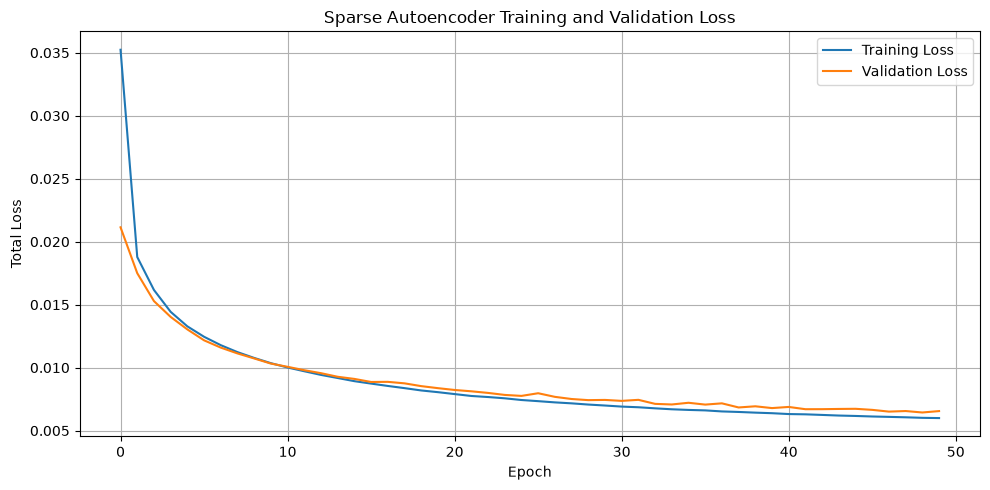

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Sparse Autoencoder Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Total Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "sparse_ae_training_curves.png",
    dpi=100
)

plt.show()

In [32]:
model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "sparse_ae.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

SparseAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

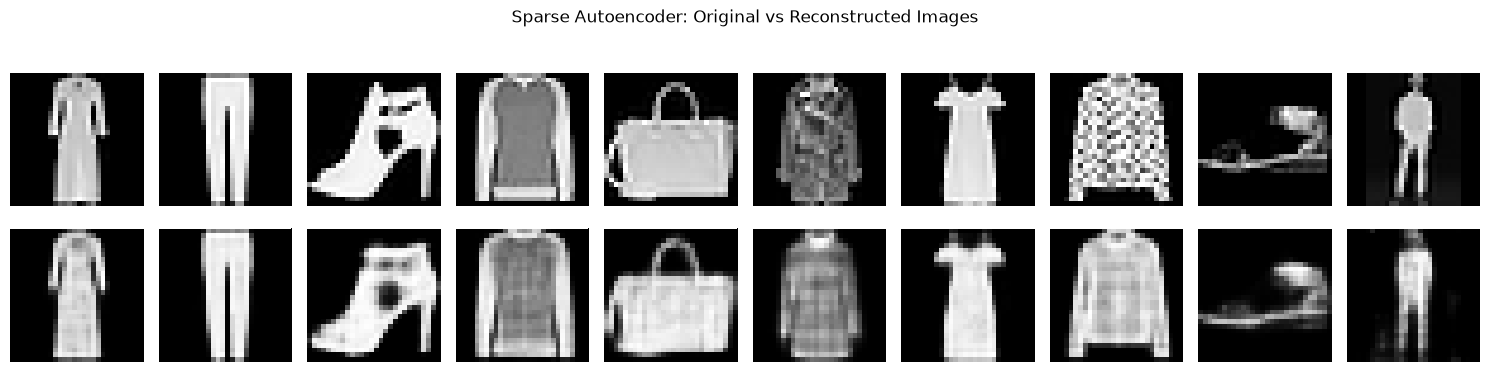

In [33]:
# Get Test Samples
images, targets = next(iter(test_loader))
images = images[:10].to(device)

# Generate Reconstructions
model.eval()

with torch.no_grad():
    reconstructed, latent = model(images)

original_images = images.cpu().view(-1, 28, 28).numpy()
reconstructed_images = reconstructed.cpu().view(-1, 28, 28).numpy()

fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for i in range(10):
    axes[0, i].imshow(original_images[i], cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed_images[i], cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=10)
axes[1, 0].set_ylabel("Reconstructed", fontsize=10)

plt.suptitle("Sparse Autoencoder: Original vs Reconstructed Images")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "sparse_ae_reconstructions.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()

In [34]:
model.eval()

latent_values = []

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        _, latent = model(images)
        latent_values.append(latent.cpu())

latent_values = torch.cat(latent_values, dim=0)

mean_activation = latent_values.abs().mean().item()
zero_activation_ratio = (
    (latent_values.abs() < 0.01).float().mean().item() * 100
)

print("Latent Representation Shape:", latent_values.shape)
print(f"Mean Absolute Activation: {mean_activation:.6f}")
print(f"Near-Zero Activation Ratio: {zero_activation_ratio:.2f}%")

Latent Representation Shape: torch.Size([7000, 64])
Mean Absolute Activation: 0.165124
Near-Zero Activation Ratio: 4.70%


In [35]:
class VanillaAutoencoder(nn.Module):
    def __init__(self, config):
        super(VanillaAutoencoder, self).__init__()

        encoder_layers = []
        encoder_dims = config["encoder"]

        for i in range(len(encoder_dims) - 1):
            encoder_layers.append(
                nn.Linear(encoder_dims[i], encoder_dims[i + 1])
            )

            if i < len(encoder_dims) - 2:
                encoder_layers.append(nn.ReLU())

        self.encoder = nn.Sequential(*encoder_layers)

        decoder_layers = []
        decoder_dims = config["decoder"]

        for i in range(len(decoder_dims) - 1):
            decoder_layers.append(
                nn.Linear(decoder_dims[i], decoder_dims[i + 1])
            )

            if i < len(decoder_dims) - 2:
                decoder_layers.append(nn.ReLU())
            else:
                decoder_layers.append(nn.Sigmoid())

        self.decoder = nn.Sequential(*decoder_layers)

    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)

        return reconstructed, latent

In [36]:
vanilla_model = VanillaAutoencoder(
    CONFIG["models"]["vanilla_ae"]
).to(device)

vanilla_model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "vanilla_ae.pth",
        map_location=device,
        weights_only=True
    )
)

vanilla_model.eval()

vanilla_latent_values = []

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        _, latent = vanilla_model(images)
        vanilla_latent_values.append(latent.cpu())

vanilla_latent_values = torch.cat(
    vanilla_latent_values,
    dim=0
)

vanilla_mean_activation = (
    vanilla_latent_values.abs().mean().item()
)

vanilla_zero_ratio = (
    (vanilla_latent_values.abs() < 0.01)
    .float().mean().item() * 100
)

print("Vanilla AE Latent Shape:", vanilla_latent_values.shape)
print(f"Mean Absolute Activation: {vanilla_mean_activation:.6f}")
print(f"Near-Zero Activation Ratio: {vanilla_zero_ratio:.2f}%")

print("\n--- Latent Activation Comparison ---")
print(f"Vanilla AE: {vanilla_zero_ratio:.2f}%")
print(f"Sparse AE:  {zero_activation_ratio:.2f}%")

Vanilla AE Latent Shape: torch.Size([7000, 64])
Mean Absolute Activation: 0.822042
Near-Zero Activation Ratio: 0.90%

--- Latent Activation Comparison ---
Vanilla AE: 0.90%
Sparse AE:  4.70%


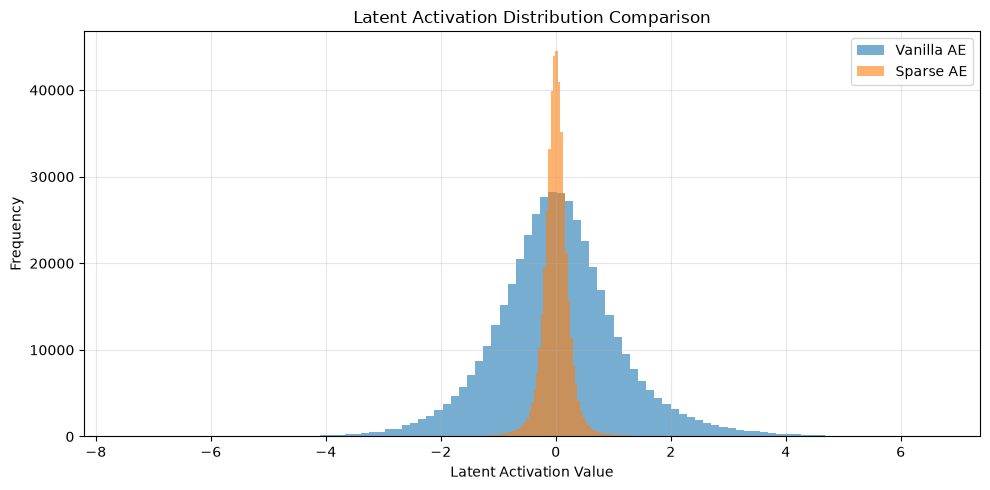

In [37]:
plt.figure(figsize=(10, 5))

plt.hist(
    vanilla_latent_values.numpy().flatten(),
    bins=100,
    alpha=0.6,
    label="Vanilla AE"
)

plt.hist(
    latent_values.numpy().flatten(),
    bins=100,
    alpha=0.6,
    label="Sparse AE"
)

plt.title("Latent Activation Distribution Comparison")
plt.xlabel("Latent Activation Value")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "ae_latent_activation_comparison.png",
    dpi=100
)

plt.show()

In [38]:
# Evaluate Vanilla AE
vanilla_model.eval()
vanilla_test_loss = 0.0

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        targets = targets.to(device)

        reconstructed, _ = vanilla_model(images)
        loss = criterion(reconstructed, targets)

        vanilla_test_loss += loss.item()

vanilla_test_loss /= len(test_loader)


# Evaluate Sparse AE
model.eval()
sparse_test_loss = 0.0

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        targets = targets.to(device)

        reconstructed, _ = model(images)
        loss = criterion(reconstructed, targets)

        sparse_test_loss += loss.item()

sparse_test_loss /= len(test_loader)


print(f"Vanilla AE Test MSE: {vanilla_test_loss:.6f}")
print(f"Sparse AE Test MSE: {sparse_test_loss:.6f}")

Vanilla AE Test MSE: 0.006145
Sparse AE Test MSE: 0.006200
